In [1]:
import os
import numpy as np

SEQ  = "RECORD@2020-11-22_12.54.38"
DATA = rf"C:\Users\daksh\Documents\SPARSE_FFT\data\{SEQ}\{SEQ}"

log_path = os.path.join(DATA, SEQ + "_events_log.rec")
print(os.path.exists(log_path))

True


In [3]:
radar = {"radar_ch0": {}, "radar_ch1": {}, "radar_ch2": {}, "radar_ch3": {}}

with open(log_path) as f:
    for line in f:
        pieces = line.split()
        if len(pieces) != 17:
            continue
        sensor = pieces[10]
        if sensor not in radar:
            continue
        sample   = int(pieces[7])
        offset   = int(pieces[13])
        datasize = int(pieces[16])
        radar[sensor][sample] = (offset, datasize)

for name in radar:
    print(name, len(radar[name]))

radar_ch0 463
radar_ch1 459
radar_ch2 462
radar_ch3 462


In [5]:
frames = []                                  # list of ch3 sample numbers that have all 4 chips

for n in radar["radar_ch3"]:
    if (n + 1) in radar["radar_ch0"] and (n + 2) in radar['radar_ch2']   and (n + 3) in radar['radar_ch1']:
        frames.append(n)

print(len(frames), frames[0], frames[-1])

452 13457 15300


In [7]:
def read_block(chip, offset, datasize):
    path = os.path.join(DATA, SEQ + f"_{chip}.bin")
    with open(path, "rb") as f:
        f.seek(offset)
        x = np.fromfile(f, dtype=np.int16, count=datasize//2)
    return x

def chip_cube(x):
    c = x[0::2] + 1j * x[1::2]
    c = np.reshape(c, (512, 4, 256), order="F")
    return c.transpose((0, 2, 1))


n = frames[0]
off3, size3 = radar["radar_ch3"][n]
off0, size0 = radar["radar_ch0"][n + 1]
off2, size2 = radar["radar_ch2"][n + 2]
off1, size1 = radar["radar_ch1"][n + 3]

c3 = chip_cube(read_block("radar_ch3", off3, size3))
c0 = chip_cube(read_block("radar_ch0", off0, size0))
c2 = chip_cube(read_block("radar_ch2", off2, size2))
c1 = chip_cube(read_block("radar_ch1", off1, size1))

cube = np.concatenate([c3, c0, c1, c2], axis=2)
print(cube.shape, cube.dtype)

(512, 256, 16) complex128


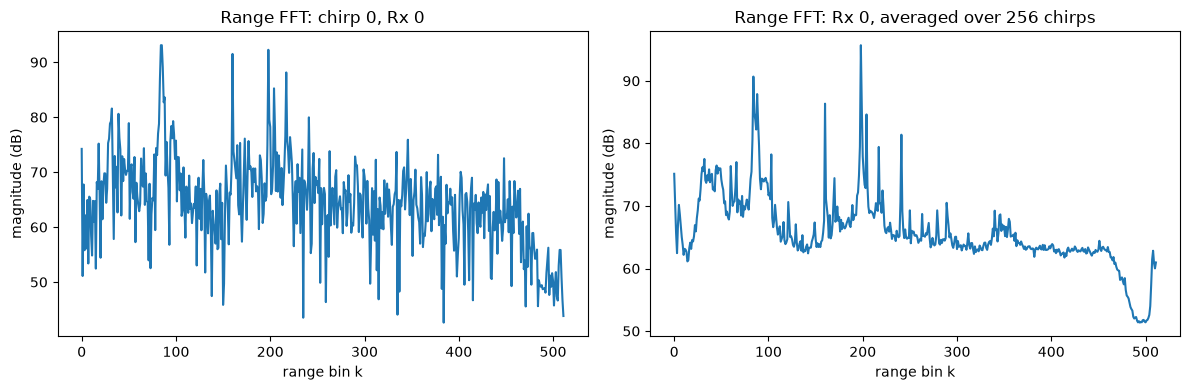

In [ ]:
import matplotlib.pyplot as plt

# 1) one chirp, one antenna
x = cube[:, 0, 0]              # all 512 samples, chirp 0, Rx 0
X = np.fft.fft(x)
mag_db = 20 * np.log10(np.abs(X) + 1e-9)

# 2) all chirps for Rx 0, then average over chirps
R = np.fft.fft(cube[:, :, 0], axis= 0)       # FFT along the sample axis
avg_db = 20 * np.log10(np.abs(R).mean(axis=1) + 1e-9)   # average over chirps

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(mag_db)
ax[0].set_title("Range FFT: chirp 0, Rx 0")
ax[1].plot(avg_db)
ax[1].set_title("Range FFT: Rx 0, averaged over 256 chirps")
for a in ax:
    a.set_xlabel("range bin k")
    a.set_ylabel("magnitude (dB)")  
plt.tight_layout()
plt.savefig(r"C:\Users\daksh\Documents\SPARSE_FFT\figures\range_fft_frame0.png", dpi=140)
plt.show()

(512, 256, 16)


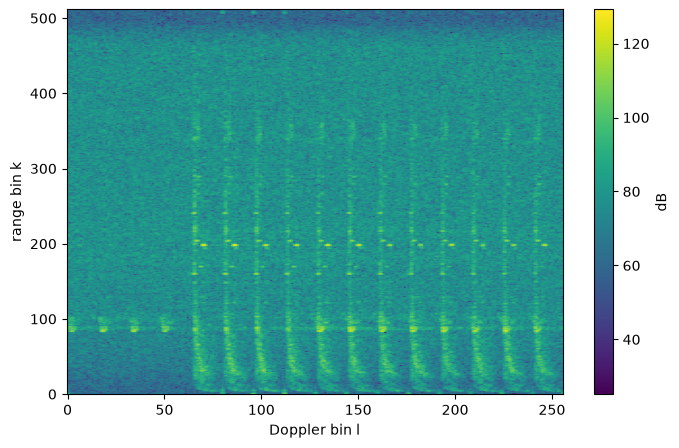

In [ ]:
# 1) DC removal: one mean per Rx antenna
cube_dc = cube - cube.mean(axis=(0, 1), keepdims=True)     # mean over samples and chirps

# 2) Hamming windows
N, M = 512, 256
w_range   = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(N) / (N - 1))
w_doppler = 0.54 - 0.46 * np.cos(2 * np.pi * np.arange(M) / (M - 1))

# 3) range window + range FFT, then Doppler window + Doppler FFT
rng = np.fft.fft(cube_dc * w_range[:, None, None], axis=0)
rd  = np.fft.fft(rng * w_doppler[None, :, None], axis=1)
print(rd.shape)

# 4) range-Doppler map for Rx 0
rd_db = 20 * np.log10(np.abs(rd[:, :, 0]) + 1e-9)
plt.figure(figsize=(8, 5))
plt.imshow(rd_db, aspect="auto", origin="lower")
plt.colorbar(label="dB")
plt.xlabel("Doppler bin l"); plt.ylabel("range bin k")
plt.savefig(r"C:\Users\daksh\Documents\SPARSE_FFT\figures\rd_map_frame0.png", dpi=140)
plt.show()  

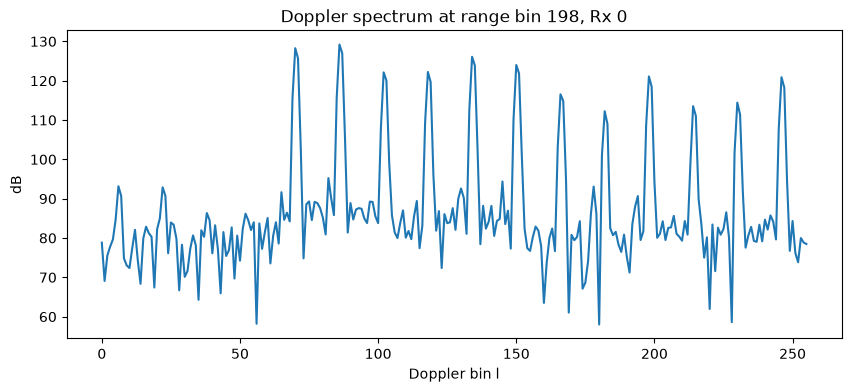

[ 70  71  86  87 102 118 134 135 150 151 198 246]
[ 1 15  1 15 16 16  1 15  1 47 48]


In [12]:
k = 198                                    # the range bin to look at
row = rd_db[k, :]                      # all 256 Doppler bins at range bin k, Rx 0 (rd_db is already (512, 256))

plt.figure(figsize=(10, 4))
plt.plot(row)
plt.xlabel("Doppler bin l"); plt.ylabel("dB")
plt.title(f"Doppler spectrum at range bin {k}, Rx 0")
plt.savefig(r"C:\Users\daksh\Documents\SPARSE_FFT\figures\doppler_row_198.png", dpi=140)
plt.show()

top12 = np.sort(np.argsort(row)[-12:])      # indices of the 12 largest values, sorted
print(top12)
print(np.diff(top12))                      # gaps between neighbouring peaks

In [13]:
from scipy.signal import find_peaks

peaks, _ = find_peaks(row, distance=2)         # min spacing between peaks, in bins
top = np.sort(peaks[np.argsort(row[peaks])[-12:]])   # keep the 12 highest peaks, sorted
print(top)
print(np.diff(top))

[ 70  86 102 118 134 150 166 182 198 214 230 246]
[16 16 16 16 16 16 16 16 16 16 16]


In [14]:
Pm = np.sum(np.abs(rd), axis=2)               # (512, 256), sum of magnitudes over the 16 Rx
P_red = Pm.reshape(512, 16, 16).sum(axis=1)    # (512, 16), the folded map

k = 198
b = np.argmax(P_red[k])                                         # folded bin of the strongest peak in row k of P_red
slots = Pm[k, b::16]                             # 16 slot values for this target
ext = np.concatenate([slots, slots[:4]])         # wrap around
cs  = np.cumsum(ext)
win = (cs[4:] - cs[:-4]) / 4                     # mean of slots j+1 ... j+4
j = np.argmin(win)
tx0_bin = 16 * j + b                                   # 16*j + b
print(b, j, tx0_bin)

6 15 246
